<a href="https://colab.research.google.com/github/Techie303/Data-Type-Memory-Performance-Benchmark-Lab/blob/main/numpy_dtype_benchmark_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NumPy Data Type Memory & Performance Benchmark Lab

**Objective:** Measure how dtype choice (int8 to int64, float16 to float64) changes **memory usage**, **speed** and **precision** in NumPy.

**NumPy topics used:** `dtype`, `astype()`, `itemsize`, `nbytes`, `np.arange`, `np.random`, `np.ones`, `np.iinfo` / `np.finfo`, overflow behaviour, performance timing.

**Notebook outline**
1. Create 1M-element arrays in 7 dtypes
2. Memory table (size, itemsize, nbytes)
3. Timing: sum and multiply
4. Overflow and precision-loss demos
5. Charts and recommendations
6. Extras: more operations, scaling with array size, real image example
7. Conclusions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import timeit

print("NumPy version:", np.__version__)

NumPy version: 2.1.3


## 1. Create the same 1M-element array in 7 dtypes
Values are 0-59 so they fit in every dtype (int8 max is 127).

In [2]:
N = 1_000_000
rng = np.random.default_rng(42)
base = rng.integers(0, 60, size=N)

dtypes = [np.int8, np.int16, np.int32, np.int64,
          np.float16, np.float32, np.float64]

arrays = {np.dtype(dt).name: base.astype(dt) for dt in dtypes}

for name, arr in arrays.items():
    print(f"{name:8s} shape={arr.shape} first5={arr[:5]}")

int8     shape=(1000000,) first5=[ 5 46 39 26 25]
int16    shape=(1000000,) first5=[ 5 46 39 26 25]
int32    shape=(1000000,) first5=[ 5 46 39 26 25]
int64    shape=(1000000,) first5=[ 5 46 39 26 25]
float16  shape=(1000000,) first5=[ 5. 46. 39. 26. 25.]
float32  shape=(1000000,) first5=[ 5. 46. 39. 26. 25.]
float64  shape=(1000000,) first5=[ 5. 46. 39. 26. 25.]


## 2. Memory table: size, itemsize and nbytes

In [3]:
rows = []
for name, arr in arrays.items():
    rows.append({
        "dtype": name,
        "size (elements)": arr.size,
        "itemsize (bytes)": arr.itemsize,
        "nbytes": arr.nbytes,
        "memory (MB)": round(arr.nbytes / 1024**2, 3),
    })

mem_df = pd.DataFrame(rows)
mem_df["vs 8-byte types"] = (mem_df["nbytes"].max() / mem_df["nbytes"]).round(1).astype(str) + "x smaller"
mem_df

,dtype,size (elements),itemsize (bytes),nbytes,memory (MB),vs 8-byte types
0,int8,1000000,1,1000000,0.954,8.0x smaller
1,int16,1000000,2,2000000,1.907,4.0x smaller
2,int32,1000000,4,4000000,3.815,2.0x smaller
3,int64,1000000,8,8000000,7.629,1.0x smaller
4,float16,1000000,2,2000000,1.907,4.0x smaller
5,float32,1000000,4,4000000,3.815,2.0x smaller
6,float64,1000000,8,8000000,7.629,1.0x smaller


`nbytes = size x itemsize`, so memory scales exactly with the number of bytes per element.

## 3. Time `sum` and `multiply` for each dtype

In [4]:
REPEAT, NUMBER = 5, 20   # best of 5 runs, 20 calls each

def best_ms(func, repeat=REPEAT, number=NUMBER):
    t = timeit.repeat(func, repeat=repeat, number=number)
    return min(t) / number * 1000   # milliseconds per call

perf_rows = []
for name, arr in arrays.items():
    perf_rows.append({
        "dtype": name,
        "sum (ms)": best_ms(lambda a=arr: a.sum()),
        "multiply (ms)": best_ms(lambda a=arr: a * 2),
    })

perf_df = pd.DataFrame(perf_rows).round(4)
perf_df

/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:53: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


,dtype,sum (ms),multiply (ms)
0,int8,0.6171,0.0896
1,int16,0.5330,0.1718
2,int32,0.5390,0.3499
3,int64,0.3417,0.7248
4,float16,2.5620,9.4264
5,float32,0.2896,0.3537
6,float64,0.3471,0.7695


## 4. Overflow and precision loss
### 4a. Integer overflow
Integers wrap around silently when a value does not fit the dtype.

In [5]:
print("200 as int8   :", np.array([200]).astype(np.int8))     # wraps to -56
print("300 as uint8  :", np.array([300]).astype(np.uint8))    # wraps to 44
print("40000 as int16:", np.array([40000]).astype(np.int16))  # wraps to -25536

a = np.array([100], dtype=np.int8)
print("int8 100 + 100 =", a + a, "(should be 200)")

print()
for dt in [np.int8, np.int16, np.int32, np.int64]:
    info = np.iinfo(dt)
    print(f"{np.dtype(dt).name:6s} range: {info.min} to {info.max}")

200 as int8   : [-56]
300 as uint8  : [44]
40000 as int16: [-25536]
int8 100 + 100 = [-56] (should be 200)

int8   range: -128 to 127
int16  range: -32768 to 32767
int32  range: -2147483648 to 2147483647
int64  range: -9223372036854775808 to 9223372036854775807


### 4b. Float precision loss

In [6]:
print("0.1 stored as:")
for dt in [np.float16, np.float32, np.float64]:
    print(f"  {np.dtype(dt).name:8s} {float(dt(0.1)):.20f}")

print()
print("float32 16777216 + 1 =", np.float32(16777216) + np.float32(1), "(the +1 is lost)")
print("float64 16777216 + 1 =", np.float64(16777216) + np.float64(1))

print()
for dt in [np.float16, np.float32, np.float64]:
    info = np.finfo(dt)
    print(f"{np.dtype(dt).name:8s} max={info.max:.3e}  eps={info.eps:.3e}")

0.1 stored as:
  float16  0.09997558593750000000
  float32  0.10000000149011611938
  float64  0.10000000000000000555

float32 16777216 + 1 = 16777216.0 (the +1 is lost)
float64 16777216 + 1 = 16777217.0

float16  max=6.550e+04  eps=9.766e-04
float32  max=3.403e+38  eps=1.192e-07
float64  max=1.798e+308  eps=2.220e-16


### 4c. Accumulation error: summing 1M values in each float dtype
float16 has a maximum of 65,504, so a large sum overflows to `inf`.

In [7]:
true_sum = base.sum()
print("True sum (int64):", true_sum)
for name in ["float16", "float32", "float64"]:
    with np.errstate(over="ignore"):
        s = arrays[name].sum()
    print(f"{name:8s} sum = {s}   error = {abs(float(s) - true_sum):.1f}")

True sum (int64): 29481082
float16  sum = inf   error = inf
float32  sum = 29481092.0   error = 10.0
float64  sum = 29481082.0   error = 0.0


## 5. Charts: memory vs time

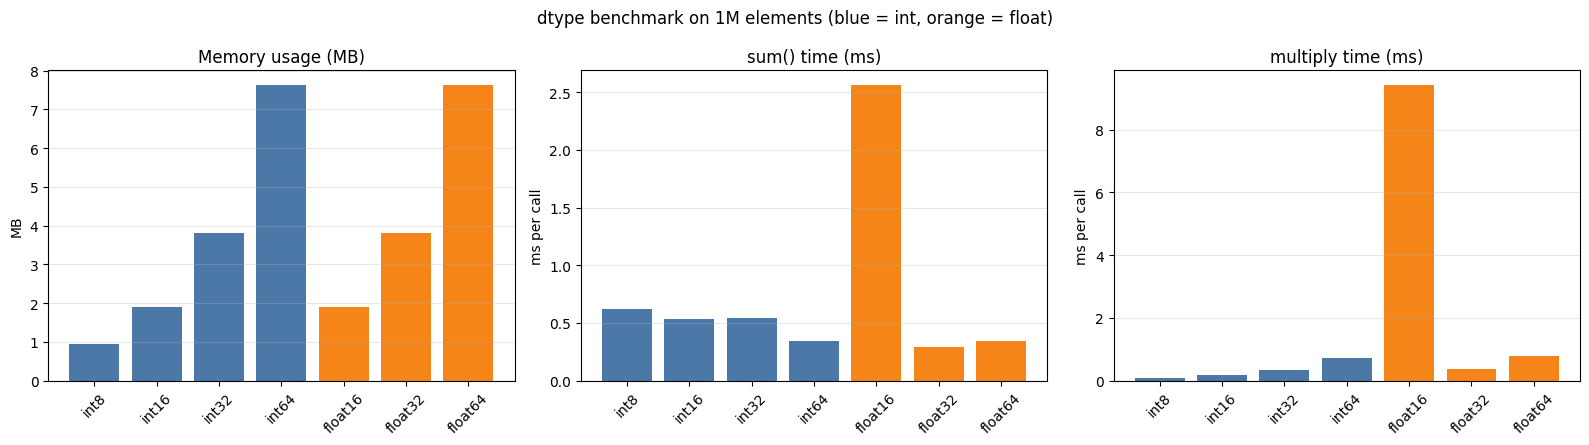

In [8]:
names = mem_df["dtype"].tolist()
colors = ["#4C78A8"] * 4 + ["#F58518"] * 3   # ints blue, floats orange

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(names, mem_df["memory (MB)"], color=colors)
axes[0].set_title("Memory usage (MB)")
axes[0].set_ylabel("MB")

axes[1].bar(names, perf_df["sum (ms)"], color=colors)
axes[1].set_title("sum() time (ms)")
axes[1].set_ylabel("ms per call")

axes[2].bar(names, perf_df["multiply (ms)"], color=colors)
axes[2].set_title("multiply time (ms)")
axes[2].set_ylabel("ms per call")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("dtype benchmark on 1M elements (blue = int, orange = float)")
plt.tight_layout()
plt.show()

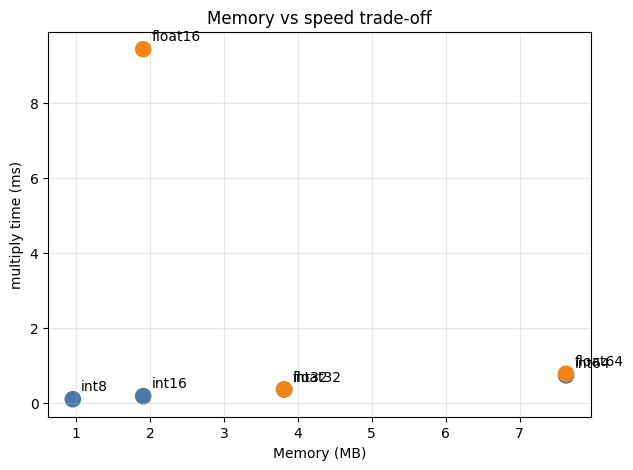

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(mem_df["memory (MB)"], perf_df["multiply (ms)"], c=colors, s=120)
for i, n in enumerate(names):
    ax.annotate(n, (mem_df["memory (MB)"][i], perf_df["multiply (ms)"][i]),
                textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("Memory (MB)")
ax.set_ylabel("multiply time (ms)")
ax.set_title("Memory vs speed trade-off")
ax.grid(alpha=0.3)
plt.show()

In [10]:
smallest, largest = mem_df["nbytes"].min(), mem_df["nbytes"].max()
print(f"Memory reduction: 8-byte types ({largest/1e6:.1f} MB) -> int8 ({smallest/1e6:.1f} MB) = {largest/smallest:.0f}x smaller")

Memory reduction: 8-byte types (8.0 MB) -> int8 (1.0 MB) = 8x smaller


## 6. Extras
### 6a. More operations: mean, sort and matrix multiply

In [11]:
M = 200  # matrix size for matmul (kept small because float16 has no fast BLAS path)
mats = {np.dtype(dt).name: rng.integers(0, 5, (M, M)).astype(dt) for dt in dtypes}

extra_rows = []
for name, arr in arrays.items():
    mat = mats[name]
    extra_rows.append({
        "dtype": name,
        "mean (ms)": best_ms(lambda a=arr: a.mean(), 3, 5),
        "sort (ms)": best_ms(lambda a=arr: np.sort(a), 3, 3),
        f"matmul {M}x{M} (ms)": best_ms(lambda m=mat: m @ m, 3, 3),
    })

extra_df = pd.DataFrame(extra_rows).round(3)
extra_df

,dtype,mean (ms),sort (ms),matmul 200x200 (ms)
0,int8,1.211,99.861,37.727
1,int16,2.329,158.902,16.014
2,int32,1.183,7.742,12.342
3,int64,2.138,13.128,15.014
4,float16,5.601,182.105,70.720
5,float32,0.301,3.917,0.322
6,float64,0.572,9.134,0.578


### 6b. How results scale with array size

In [12]:
sizes = [100_000, 1_000_000, 10_000_000]
scale = {np.dtype(dt).name: [] for dt in dtypes}

for n in sizes:
    data = rng.integers(0, 60, size=n)
    for dt in dtypes:
        arr = data.astype(dt)
        scale[np.dtype(dt).name].append(best_ms(lambda a=arr: a * 2, 3, 3))
    del data

scale_df = pd.DataFrame(scale, index=[f"{s:,}" for s in sizes]).round(3)
scale_df.index.name = "array size"
scale_df

,int8,int16,int32,int64,float16,float32,float64
array size,,,,,,,
"100,000",0.011,0.013,0.059,0.085,1.525,0.023,0.077
"1,000,000",0.101,0.174,0.552,0.915,9.453,0.355,0.928
"10,000,000",1.043,3.421,12.026,25.883,94.350,12.102,24.940


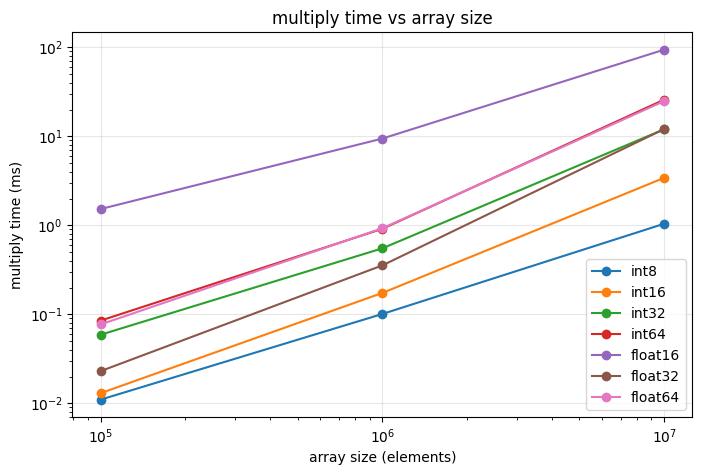

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in scale_df.columns:
    ax.plot(sizes, scale_df[name], marker="o", label=name)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("array size (elements)")
ax.set_ylabel("multiply time (ms)")
ax.set_title("multiply time vs array size")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

### 6c. Real-world example: image memory (uint8 vs float32 vs float64)
A 1000x1000 RGB image is a 3D array. Most images are stored as `uint8`.

In [14]:
img_u8 = rng.integers(0, 256, (1000, 1000, 3), dtype=np.uint8)
img_f32 = img_u8.astype(np.float32) / 255
img_f64 = img_u8.astype(np.float64) / 255

for label, im in [("uint8", img_u8), ("float32", img_f32), ("float64", img_f64)]:
    print(f"{label:8s} shape={im.shape}  {im.nbytes/1024**2:6.2f} MB")

print(f"\nfloat64 image uses {img_f64.nbytes // img_u8.nbytes}x the memory of the uint8 image")

# Brighten safely: cast up, add, clip, cast back
bright = np.clip(img_u8.astype(np.int16) + 60, 0, 255).astype(np.uint8)

# The unsafe way overflows and wraps around
broken = img_u8 + np.uint8(60)
print("pixel 230 +60 safe  :", np.clip(230 + 60, 0, 255))
print("pixel 230 +60 uint8 :", np.uint8(230) + np.uint8(60), "(overflow wrap-around)")

uint8    shape=(1000, 1000, 3)    2.86 MB
float32  shape=(1000, 1000, 3)   11.44 MB
float64  shape=(1000, 1000, 3)   22.89 MB

float64 image uses 8x the memory of the uint8 image
pixel 230 +60 safe  : 255
pixel 230 +60 uint8 : 34 (overflow wrap-around)


/tmp/ipykernel_3252/3878882094.py:16: RuntimeWarning: overflow encountered in scalar add
  print("pixel 230 +60 uint8 :", np.uint8(230) + np.uint8(60), "(overflow wrap-around)")


## 7. Recommendations and conclusions
| Situation | Suggested dtype |
|---|---|
| Small whole numbers (ages, ratings, flags) | `int8` |
| Image pixels (0-255) | `uint8` |
| Counts up to about 30,000 | `int16` |
| General integers, indexes | `int32` / `int64` |
| Scientific or financial maths needing accuracy | `float64` |
| Large ML or image arrays where memory matters | `float32` |
| Storage only, never accumulated | `float16` |

**Key findings**
- Memory scales exactly with itemsize: int8 uses 8x less memory than int64 or float64.
- Smaller is not always faster. float16 was the slowest dtype in the timing tests because most CPUs have no native float16 arithmetic, so NumPy emulates it.
- Integers overflow silently (int8 200 becomes -56). Always check ranges with `np.iinfo` before downcasting.
- float16 summing 1M values overflows to `inf`; float32 loses small increments beyond 2^24.
- Rule of thumb: pick the smallest dtype that safely holds your data range, then measure on your own workload.

---
**Resume line:** Benchmarked NumPy dtypes on 1M-element arrays, reducing memory by up to 8x with optimal type casting while documenting overflow and precision trade-offs.